In [12]:
# =============================================================================
# CELL 0 -- Configuration, imports and style
#
# Single-skewer companion to 01.5_TNG50_individual.ipynb, built so that FIG 2
# (plots/HCD_detection_altHalo.png, reproduced exactly as 01.5_'s Cell 8) can
# be regenerated for a different impact parameter or axis WITHOUT re-running
# 01.5_'s Cell 4 (the 12-skewer x 2-b FIG 1 batch, 24 skewers) or the Cell
# 3b/3c resolution-check diagnostic. Only what those figures actually need is
# here:
#
#   CELL 1  capture_cells / merge_captures      (unchanged from 01.5_)
#   CELL 2  impact-parameter grid, sightline geometry (unchanged from 01.5_)
#   CELL 3  EXTRACTION -- the DEFAULT sightline (b=B_TARGET, axis=AXIS, a
#           random position), three filter passes through the C
#           interpolator. Also seeds PEAK_SMOOTH_KMS/PEAK_CONTRAST for
#           CELL 4 below (halo/b/axis-independent constants).
#   CELL 4  SEARCH -- scans a grid of (b, axis, position) for THIS SAME halo
#           for a sightline with exactly one accepted (non-blended) region
#           in the Sub-DLA column-density range, then re-runs the real
#           extraction on the winner, overwriting CELL 3's res/meta/AXIS/
#           B_USED/position. The only other cell that reads the snapshot.
#   CELL 5  halo-rest-frame alignment (cheap, numpy only)
#   CELL 6  FIG 2  (plots/HCD_detection_altHalo.png) -- the 2-panel version
#   CELL 7  position-space prep (chi_hcd/chi_for/basins) for CELL 8
#   CELL 8  FIG 2d (plots/HCD_detection_subDLA_3panel_systems.pdf) -- the
#           3-panel version: real-space column per cell coloured by system,
#           velocity-space column with the smoothed/segmented profile, flux
#
# Same halo (HALO_ID = 25) as 01.5_'s FIG 2. CELL 3's B_TARGET is only a
# starting point for CELL 4's search now, not the final impact parameter --
# see CELL 4 for the sightline actually used by CELL 5 onward.
# =============================================================================
%matplotlib widget

import os
import sys
from contextlib import contextmanager

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

REPO_DIR = os.path.abspath("..")          # notebooks_TNG/ -> FakeSpectra_DLAs/
sys.path.insert(0, os.path.join(REPO_DIR, "tools"))

import utils
import radii_skewers
from fake_spectra import spectra

if not hasattr(spectra, "HCD_ALGORITHMS"):
    raise ImportError(f"{spectra.__file__} is not the HCD fork "
                      "(no HCD_ALGORITHMS)")
print("using:", spectra.__file__)
print("algorithms:", spectra.HCD_ALGORITHMS)

# --- simulation --------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"   # no "/output": groups_025/ lives here
SNAP_NUM  = 25                            # z ~ 3.01
SIM_TYPE  = "TNG"
RES_KMS   = 10.0                          # production sampling

HCD_ALGORITHM = "peaks+blend"
# All three filter modes must share a kernel: the Voronoi kernel rebuilds its
# segments from whatever particles it is given, so a filtered subset would
# silently redistribute the removed volume onto the survivors.
KERNEL = "tophat"

# --- what to plot ------------------------------------------------------------
HALO_ID  = 25          # fixed: same halo as 01.5_'s FIG 2
POSITION = None        # None -> random among Right/Left/Top/Bottom (seeded)
SEED     = 12345

NUM_PARAM_IMPACTS   = 30
RANGE_PARAM_IMPACTS = (0.01, 50.0)
HCD_LOG_NHI = 17.2

AXIS      = 1             # 1-indexed, as fake_spectra expects (1 = x)
B_TARGET  = 0.12          # snapped to the nearest production grid value
XLIM_FIG2 = None          # e.g. (-2000, 2000) km/s
FINE_ALIGN = True         # re-centre on the absorber, per Sec. 2.4
MAP_SLAB_R200 = 5.0        # +/-N R200 association window, for CELL 8's panel 1
                           # shading -- matches halo_radius_cut in CELL 3/4

PLOT_DIR = os.path.join(REPO_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
DEFINITIVES_DIR = os.path.join(REPO_DIR, "definitives")   # CELL 8's output
os.makedirs(DEFINITIVES_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# --- style (identical to 01.5_) ----------------------------------------------
plt.rc('font', family='serif', size=16)
plt.rcParams.update({
    "mathtext.fontset": "cm", "text.usetex": False,
    "axes.linewidth": 1.6, "axes.grid": False,
    "axes.labelsize": 19, "legend.fontsize": 15,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.major.width": 1.4, "ytick.major.width": 1.4,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "legend.frameon": True, "legend.framealpha": 0.92,
    "figure.dpi": 72, "savefig.dpi": 300, "savefig.bbox": "tight",
})

# Okabe-Ito, verbatim from the manuscript preamble.
colors = [
    "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
    "#D55E00", "#CC79A7", "#000000", "#999999", "#553388",
]
OI = {"orange": colors[0], "sky": colors[1], "green": colors[2],
      "yellow": colors[3], "blue": colors[4], "vermillion": colors[5],
      "purple": colors[6], "black": colors[7], "grey": colors[8],
      "violet": colors[9]}
plt.rcParams["axes.prop_cycle"] = mpl.cycler(color=colors)


using: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
algorithms: ('peaks', 'peaks+blend', 'region_growing')


In [13]:
# =============================================================================
# CELL 1 -- Capture the cells fake_spectra actually interpolated
#
# Unchanged from 01.5_TNG50_individual.ipynb's Cell 1.
#
# The fork discards its internal mask, so we read it off the three filter modes:
#   "None"        -> every cell near the sightline
#   "HCD_only"    -> the cells the filter flagged
#   "Forest_only" -> the complement
#
# THREE TRAPS:
#  1. Shapes. Each mode runs three passes (tau, column density, temperature);
#     only the tau pass carries full velocities and temperatures. Keep get_tau
#     only, or concatenating mixes (N,3) with (1,).
#  2. Units. elem_den is in code units, and in the get_temp pass it is not even
#     n_HI. Physical n_HI = (elem_den / rscale) * amumass.
#  3. Re-entrancy. Under peaks+blend the fork's _blend_test calls the
#     interpolator once per CANDIDATE basin while still deciding the mask.
#     Those are hypotheses, not the answer; drop anything captured inside it.
# =============================================================================
@contextmanager
def suppress_c_stdout():
    """Silence the C interpolator's progress printing (it writes to fd 1)."""
    sys.stdout.flush()
    saved = os.dup(1)
    devnull = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


@contextmanager
def capture_cells(store):
    original_interp = spectra.Spectra._do_interpolation_work
    original_blend = getattr(spectra.Spectra, "_blend_test", None)
    state = {"in_blend": False, "n_blend": 0}

    def interp_wrapper(self, pos, vel, elem_den, temp, hh, amumass, line,
                       get_tau, custom_axis=None, custom_cofm=None):
        if state["in_blend"]:
            state["n_blend"] += 1
        else:
            store.append(dict(
                get_tau=bool(get_tau), amumass=float(amumass),
                rscale=float(self.rscale),
                pos=np.array(pos, copy=True), vel=np.array(vel, copy=True),
                den=np.array(elem_den, copy=True),
                temp=np.array(temp, copy=True)))
        return original_interp(self, pos, vel, elem_den, temp, hh, amumass,
                               line, get_tau, custom_axis=custom_axis,
                               custom_cofm=custom_cofm)

    def blend_wrapper(self, *a, **kw):
        prev = state["in_blend"]
        state["in_blend"] = True
        try:
            return original_blend(self, *a, **kw)
        finally:
            state["in_blend"] = prev

    spectra.Spectra._do_interpolation_work = interp_wrapper
    if original_blend is not None:
        spectra.Spectra._blend_test = blend_wrapper
    try:
        yield store
    finally:
        spectra.Spectra._do_interpolation_work = original_interp
        if original_blend is not None:
            spectra.Spectra._blend_test = original_blend
        if state["n_blend"]:
            print(f"    (dropped {state['n_blend']} blend-test interpolations)")


EMPTY_CELLS = dict(pos=np.empty((0, 3)), vel=np.empty((0, 3)),
                   nHI=np.empty(0), temp=np.empty(0))


def merge_captures(store):
    """Keep the get_tau pass, convert the density to physical n_HI [cm^-3]."""
    chunks = [c for c in store if c["get_tau"]]
    if not chunks:
        return dict(EMPTY_CELLS)
    for c in chunks:
        n = c["pos"].shape[0]
        if c["vel"].shape[0] != n or c["temp"].shape[0] != n:
            raise RuntimeError("ragged get_tau chunk; the fork's interpolation "
                               "signature changed -- update this wrapper")
    out = {k: np.concatenate([c[k] for c in chunks], axis=0)
           for k in ("pos", "vel", "temp")}
    out["nHI"] = np.concatenate(
        [(c["den"] / c["rscale"]) * c["amumass"] for c in chunks], axis=0)
    return out


In [14]:
# =============================================================================
# CELL 2 -- Impact-parameter grid and sightline geometry
#
# Same snap_impact/wrap/sightline_for as 01.5_'s Cell 2. HALO_ID is fixed
# here, so the halo lookup in CELL 3 is a single get_halo_properties call
# rather than 01.5_'s stratified-sample search loop.
# =============================================================================
def build_r_multipliers(n_impacts, impact_min, impact_max):
    return np.insert(np.logspace(np.log10(impact_min), np.log10(impact_max),
                                 n_impacts), 0, 0.0)


R_MULTIPLIERS = build_r_multipliers(NUM_PARAM_IMPACTS, *RANGE_PARAM_IMPACTS)


def snap_impact(b_target, grid=R_MULTIPLIERS):
    """Nearest grid value to b_target, in log space (the grid is log-spaced)."""
    pos = grid[grid > 0]
    k = int(np.argmin(np.abs(np.log10(pos) - np.log10(b_target))))
    return float(pos[k]), k


def wrap(d, period):
    """Signed separation on a periodic axis, in (-period/2, +period/2]."""
    return (np.asarray(d) + period / 2.0) % period - period / 2.0


B_USED, B_INDEX = snap_impact(B_TARGET)
print(f"b: {B_TARGET} -> {B_USED:.4f} R200 (grid index {B_INDEX})")

ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
finder = utils.HaloFinder(ctx)

for _p in (os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}",
                        f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"),
           os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"not found: {_p}\nCheck BASE_PATH={BASE_PATH!r}")

POSITION_TAGS = ("Right", "Left", "Top", "Bottom")
position = POSITION if POSITION is not None else str(rng.choice(POSITION_TAGS))
print(f"sightline: axis {AXIS} (1 = x), position {position}")


def sightline_for(halo_info, axis_1indexed, b_mult, tag):
    """cofm and axis arrays for one skewer, using the production geometry."""
    g = radii_skewers.SkewerGeometry(ctx, halo_info)
    for sk in g.generate_skewers(r_multiplier=b_mult):
        if sk['axis'] == axis_1indexed - 1 and sk['position_tag'] == tag:
            cofm = np.mod(np.asarray(halo_info['cm'], float) + sk['offset_vec'],
                          halo_info['box_size'])
            return (np.array([cofm], dtype=np.float64),
                    np.array([axis_1indexed], dtype=np.int32), sk)
    raise RuntimeError(f"no skewer with axis={axis_1indexed}, tag={tag}")


b: 0.12 -> 0.1048 R200 (grid index 8)
sightline: axis 1 (1 = x), position Top


In [15]:
# =============================================================================
# CELL 3 -- EXTRACTION: the one sightline, three filter passes
#
# This is the only cell that touches the snapshot (three spectra.Spectra()
# calls -- filter_mode None / HCD_only / Forest_only -- sharing one sightline).
# RE-RUN THIS CELL whenever AXIS or B_TARGET changes: both change cofm/axis,
# i.e. which particles the C interpolator reads. A change to a downstream-only
# quantity (FINE_ALIGN, XLIM_FIG2, plot styling) does NOT need this cell
# re-run -- just re-run CELL 4 and CELL 5 below.
# =============================================================================
MODES = ("None", "HCD_only", "Forest_only")


def run_one_sightline(halo_info, cofm, axis_arr, res_kms=None):
    res_kms = RES_KMS if res_kms is None else res_kms
    out, meta = {}, {}
    for mode in MODES:
        store = []
        with capture_cells(store), suppress_c_stdout():
            ss = spectra.Spectra(
                int(SNAP_NUM), BASE_PATH, cofm=cofm, axis=axis_arr,
                res=res_kms, savefile=f"unused_{halo_info['id']}_{mode}.hdf5",
                reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
                filter_mode=mode, hcd_algorithm=HCD_ALGORITHM,
                units=ctx.units, halo_r200=float(halo_info['r200']),
                halo_radius_cut=utils.HALO_RADIUS_CUT,
                **utils.SPECTRA_GAS_KWARGS)    # same star-forming gas model as the pipeline
            tau = ss.get_tau("H", 1, 1215)[0]
            colden = ss.get_col_density("H", 1)[0]
            temp = ss.get_temp("H", 1)[0]

        out[mode] = dict(flux=np.exp(-tau), tau=tau, colden=colden, temp=temp,
                         cells=merge_captures(store))

        if not meta:      # geometry and cosmology: identical in all modes
            meta = dict(nbins=ss.nbins, vmax=ss.vmax, velfac=ss.velfac,
                        box=ss.box, red=ss.red, rscale=ss.rscale)
        if mode == "HCD_only":
            meta.update(
                selection_thresh=ss.hcd_selection_thresh,
                peak_smooth_kms=ss.hcd_peak_smooth_kms,
                peak_contrast=ss.hcd_peak_contrast,
                blend_flux_thresh=ss.hcd_blend_flux_thresh,
                basin_info=dict(getattr(ss, "hcd_basin_info", {})))

        tot = colden.sum()
        print(f"  {mode:12s} -> {out[mode]['cells']['pos'].shape[0]:6d} cells, "
              f"log10 N_HI = {np.log10(tot) if tot > 0 else -np.inf:.2f}")
    return out, meta


halo_info = finder.get_halo_properties(int(HALO_ID))
cofm, axis_arr, sk_info = sightline_for(halo_info, AXIS, B_USED, position)
r200 = float(halo_info['r200'])
print(f"halo {HALO_ID}  log10 M200 = "
      f"{np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}  R200 = "
      f"{r200 * ctx.length_unit_kpc:.1f} ckpc/h")

res, meta = run_one_sightline(halo_info, cofm, axis_arr)

n_tot = res["HCD_only"]["colden"].sum()
has_hcd = n_tot > 0 and np.log10(n_tot) >= HCD_LOG_NHI
n_basins = len(meta.get('basin_info', {}).get(0, []))
print(f"HCD present: {has_hcd}  ({n_basins} basin(s) at production resolution)")

# The decomposition must be a partition. A mismatch means the three modes did
# not see the same particle set, almost always a kernel mismatch.
na = res["None"]["cells"]["pos"].shape[0]
nh = res["HCD_only"]["cells"]["pos"].shape[0]
nf = res["Forest_only"]["cells"]["pos"].shape[0]
print(f"cells: total={na}, HCD={nh}, forest={nf}, HCD+forest-total={nh+nf-na}")
c_all = res["None"]["colden"].sum()
if c_all > 0:
    c_sum = res["HCD_only"]["colden"].sum() + res["Forest_only"]["colden"].sum()
    print(f"N_HI closure: (HCD+forest)/total - 1 = {c_sum / c_all - 1:.3e}")


halo 25  log10 M200 = 12.21  R200 = 244.8 ckpc/h
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.6 percent done
rank = 0 | Interpolation 16.4 percent done
rank = 0 | Interpolation 17.2 percent done
rank = 0 | Interp

In [16]:
# =============================================================================
# CELL 4 -- SEARCH: a clean, single-region Sub-DLA example (same halo)
#
# CELL 3's default sightline (b=B_TARGET, axis=AXIS, a random position) is
# whatever it happens to be -- not guaranteed to be a clean Sub-DLA. This
# cell searches the SAME halo (HALO_ID, fixed in CELL 0) over a grid of
# (impact parameter, axis, position) for a sightline whose HCD-isolation
# pipeline accepts EXACTLY ONE region (no blended companions) with a total
# column density in the Sub-DLA range, log10 N_HI in [19, 20.3) -- the class
# whose covering fraction peaks around b ~ 0.17 R200 (paper Sec. 3.1.1).
#
# SAME BATCHING TRICK AS 01.5_'s CELL 12 ("SEARCH FOR A BETTER FIG 2d
# EXAMPLE"): one spectra.Spectra(filter_mode="None") call gets a raw
# column-density profile for every candidate sightline in a SINGLE snapshot
# read (the read, not the sightline count, dominates the wall time -- see
# 01.5_'s Cell 12 note), and the accept/reject decision is reconstructed by
# hand from that profile using the exact watershed the fork itself runs
# (_velocity_watershed, spectra.py:1032) plus its exact selection threshold
# (spectra.HCD_SELECTION_THRESH) and contrast/smoothing (PEAK_CONTRAST /
# PEAK_SMOOTH_KMS, read off CELL 3's default sightline -- both are
# halo/axis/b-independent constants, see 01.5_'s Cell 12). Only a
# Hubble-flow-only proxy for the real in_window test is possible here (no
# per-particle positions in a filter_mode="None" batch) -- same caveat as
# 01.5_'s Cell 12; the WINNING candidate gets the real, fork-computed answer
# for free below, when CELL 3's run_one_sightline is re-run on it.
#
# Axis varies across candidates here (unlike 01.5_'s Cell 12, which only
# varied halo at fixed axis), so the Hubble-flow proxy uses a PER-CANDIDATE
# k_los = axis-1, not a single global one.
# =============================================================================
from scipy.ndimage import gaussian_filter1d

SUBDLA_LOGNHI = (19.0, 20.3)
SEARCH_B_RANGE = (0.05, 0.30)   # around the sub-DLA covering-fraction peak
HALO_RADIUS_CUT_SEARCH = 5.0    # matches halo_radius_cut in run_one_sightline

search_b = [b for b in R_MULTIPLIERS
           if b > 0 and SEARCH_B_RANGE[0] <= b <= SEARCH_B_RANGE[1]]
search_axes = (1, 2, 3)
search_tags = POSITION_TAGS

cofm_rows, axis_rows, cand_rows = [], [], []
for b in search_b:
    for ax in search_axes:
        for tag in search_tags:
            cofm1, axis1, sk1 = sightline_for(halo_info, ax, b, tag)
            cofm_rows.append(cofm1[0])
            axis_rows.append(int(axis1[0]))
            cand_rows.append((b, ax, tag, sk1))

cofm_batch = np.asarray(cofm_rows, dtype=np.float64)
axis_batch = np.asarray(axis_rows, dtype=np.int32)

print(f"one batched read for {len(cofm_rows)} candidate sightlines "
      f"({len(search_b)} b x {len(search_axes)} axes x {len(search_tags)} "
      "positions, same halo, filter_mode='None')...")
with suppress_c_stdout():
    ss_search = spectra.Spectra(
        int(SNAP_NUM), BASE_PATH, cofm=cofm_batch, axis=axis_batch,
        res=RES_KMS, savefile="unused_search_subdla.hdf5",
        reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
        filter_mode="None", hcd_algorithm=HCD_ALGORITHM, units=ctx.units,
        **utils.SPECTRA_GAS_KWARGS)    # same star-forming gas model as the pipeline
    colden_search = ss_search.get_col_density("H", 1)

box_s, velfac_s = ss_search.box, ss_search.velfac
vmax_s, nbins_s = ss_search.vmax, ss_search.nbins
dv_bin_s = vmax_s / nbins_s
PEAK_SMOOTH_KMS = meta['peak_smooth_kms']   # halo/b/axis-independent
PEAK_CONTRAST = meta['peak_contrast']
HCD_THRESH = spectra.HCD_SELECTION_THRESH
sigma_pix_s = PEAK_SMOOTH_KMS / dv_bin_s

hits = []
for k, (b, ax, tag, sk1) in enumerate(cand_rows):
    prof_raw_k = np.asarray(colden_search[k], dtype=float)
    prof_smooth_k = (gaussian_filter1d(prof_raw_k, sigma_pix_s, mode='wrap')
                     if sigma_pix_s > 1e-3 else prof_raw_k.copy())
    labels_k, peak_pix_k = spectra.Spectra._velocity_watershed(
        prof_smooth_k, PEAK_CONTRAST)
    n_bas_k = max(int(labels_k.max()) + 1, 0) if labels_k.size else 0
    if n_bas_k == 0:
        continue
    basin_N_k = np.bincount(labels_k, weights=prof_raw_k, minlength=n_bas_k)
    peak_kms_k = peak_pix_k * dv_bin_s

    k_los_k = ax - 1
    v_cosmo_k = (halo_info['cm'][k_los_k] / box_s) * vmax_s
    chi_peak_k = wrap(peak_kms_k - v_cosmo_k, vmax_s) / velfac_s
    in_window_k = np.abs(chi_peak_k) <= HALO_RADIUS_CUT_SEARCH * r200

    accepted_k = (basin_N_k >= HCD_THRESH) & in_window_k
    if accepted_k.sum() != 1:
        continue
    i_acc = int(np.flatnonzero(accepted_k)[0])
    logNHI_k = np.log10(max(basin_N_k[i_acc], 1e-300))
    if not (SUBDLA_LOGNHI[0] <= logNHI_k < SUBDLA_LOGNHI[1]):
        continue

    hits.append(dict(b=b, axis=ax, tag=tag, sk=sk1, cofm=cofm_batch[k:k + 1],
                     axis_arr=axis_batch[k:k + 1], logNHI=logNHI_k,
                     n_basins=n_bas_k))

print(f"\n{len(hits)} candidate(s) with exactly one accepted region in the "
      f"Sub-DLA range (log N_HI in {SUBDLA_LOGNHI}):")
print(f"{'b [R200]':>9} {'axis':>5} {'tag':>7} {'#basins':>8} {'log NHI':>8}")
for h in hits[:15]:
    print(f"{h['b']:9.4f} {h['axis']:5d} {h['tag']:>7} {h['n_basins']:8d} "
          f"{h['logNHI']:8.2f}")

if not hits:
    raise RuntimeError(
        "no single-region Sub-DLA sightline found for this halo in the "
        "searched (b, axis, position) grid -- widen SEARCH_B_RANGE above, "
        "or pick a different halo via HALO_ID in CELL 0.")

# --- VERIFY, FOR REAL, IN ORDER OF PROXIMITY TO THE MIDDLE OF THE RANGE ----
# The screen above only checks basin_N >= HCD_THRESH -- it does NOT run the
# blend test of Sec. 2.3 (step 5), which can mark sub-threshold NEIGHBOURING
# basins as "accepted" too once they turn out to be inseparable in flux from
# the main one. So "exactly one basin over threshold" (the screen) and
# "exactly one basin accepted" (the fork's real answer) are different
# statements, and only the second is the "only 1 region identified" we
# actually want. Verified here with ONE filter_mode="HCD_only" pass per
# candidate (get_col_density alone triggers _hcd_peak_mask and therefore
# hcd_basin_info -- no need for get_tau/get_temp just to verify), i.e. 1/3
# the cost of a full run_one_sightline call, tried in order until one
# candidate's REAL accepted count is 1 (and its real column density is still
# in the Sub-DLA range, since blending can also pull the total up).
def verify_hcd_only(halo_info, cofm1, axis_arr1):
    with suppress_c_stdout():
        ss_v = spectra.Spectra(
            int(SNAP_NUM), BASE_PATH, cofm=cofm1, axis=axis_arr1,
            res=RES_KMS, savefile=f"unused_verify_{halo_info['id']}.hdf5",
            reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
            filter_mode="HCD_only", hcd_algorithm=HCD_ALGORITHM,
            units=ctx.units, halo_r200=float(halo_info['r200']),
            halo_radius_cut=utils.HALO_RADIUS_CUT,
            **utils.SPECTRA_GAS_KWARGS)    # same star-forming gas model as the pipeline
        colden_v = ss_v.get_col_density("H", 1)[0]
    basins_v = list(getattr(ss_v, "hcd_basin_info", {}).get(0, []))
    n_acc_v = sum(bb['accepted'] for bb in basins_v)
    tot_v = colden_v.sum()
    logNHI_v = float(np.log10(tot_v)) if tot_v > 0 else -np.inf
    return n_acc_v, logNHI_v, len(basins_v)


target_logNHI = 0.5 * (SUBDLA_LOGNHI[0] + SUBDLA_LOGNHI[1])
hits.sort(key=lambda h: abs(h['logNHI'] - target_logNHI))

print(f"\nverifying candidates in order of proximity to log N_HI = "
      f"{target_logNHI:.2f} (real accept/reject, not the screen above):")
winner = None
for h in hits:
    n_acc_v, logNHI_v, n_bas_v = verify_hcd_only(halo_info, h['cofm'],
                                                 h['axis_arr'])
    print(f"  b={h['b']:.4f} axis={h['axis']} {h['tag']:>7}: "
          f"real accepted={n_acc_v}, real log N_HI={logNHI_v:.2f} "
          f"(screened {h['logNHI']:.2f}, {n_bas_v} basin(s) total)")
    if n_acc_v == 1 and SUBDLA_LOGNHI[0] <= logNHI_v < SUBDLA_LOGNHI[1]:
        winner = h
        break

if winner is None:
    raise RuntimeError(
        "none of the screened candidates has exactly one ACCEPTED region "
        "once the real blend test is applied -- widen SEARCH_B_RANGE above, "
        "or pick a different halo via HALO_ID in CELL 0.")

print(f"\n--> picked b={winner['b']:.4f} R200, axis={winner['axis']}, "
      f"{winner['tag']}  -- verified single-region Sub-DLA")

# Re-run the REAL, fork-computed extraction on the winner (all 3 modes this
# time, for the plots below) -- overwrites CELL 3's res/meta/cofm/axis_arr/
# B_USED/AXIS/position/sk_info, so every cell below (alignment, both plots)
# now describes THIS sightline.
B_USED = winner['b']
AXIS = winner['axis']
position = winner['tag']
sk_info = winner['sk']
cofm, axis_arr = winner['cofm'], winner['axis_arr']

res, meta = run_one_sightline(halo_info, cofm, axis_arr)
basins_confirm = meta.get('basin_info', {}).get(0, [])
n_accepted_confirm = sum(bb['accepted'] for bb in basins_confirm)
n_tot = res["HCD_only"]["colden"].sum()
print(f"confirmed: log10 N_HI = "
      f"{np.log10(n_tot) if n_tot > 0 else -np.inf:.2f}, "
      f"{len(basins_confirm)} basin(s) found, {n_accepted_confirm} accepted")
assert n_accepted_confirm == 1, "re-extraction disagrees with verify_hcd_only"


one batched read for 72 candidate sightlines (6 b x 3 axes x 4 positions, same halo, filter_mode='None')...
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.6 percent done
rank = 0 | Interpolation 16.4 percent done
r

In [17]:
# =============================================================================
# CELL 5 -- halo-rest-frame alignment (cheap, numpy only)
#
# Re-run after CELL 3, or on its own after changing FINE_ALIGN / XLIM_FIG2.
# Unchanged from 01.5_TNG50_individual.ipynb's Cell 7.
# =============================================================================
k_los = AXIS - 1
box = meta['box']
a_of_z = 1.0 / (1.0 + meta['red'])

v_cosmo = (halo_info['cm'][k_los] / box) * meta['vmax']
v_pec_halo = halo_info['vel_raw'][k_los] * np.sqrt(a_of_z)
V_SYS = v_cosmo + v_pec_halo

v_axis = np.arange(meta['nbins']) * (meta['vmax'] / meta['nbins'])
v_grid = np.linspace(-meta['vmax'] / 2.0, meta['vmax'] / 2.0, meta['nbins'])


def center_on_halo(y):
    dv = wrap(v_axis - V_SYS, meta['vmax'])
    o = np.argsort(dv)
    dvs, ys = dv[o], np.asarray(y, dtype=float)[o]
    dvs = np.concatenate([dvs - meta['vmax'], dvs, dvs + meta['vmax']])
    ys = np.concatenate([ys, ys, ys])
    return np.interp(v_grid, dvs, ys)


def cell_coords(cells):
    """(Delta v [km/s], n_HI [cm^-3]) for one captured cell set, halo frame."""
    if cells['pos'].shape[0] == 0:
        return np.empty(0), np.empty(0)
    chi = wrap(cells['pos'][:, k_los] - halo_info['cm'][k_los], box)
    return (wrap(chi * meta['velfac'] + cells['vel'][:, k_los] - v_pec_halo,
                 meta['vmax']),
            cells['nHI'])


flux_c = {m: center_on_halo(res[m]["flux"]) for m in MODES}
x_hcd, n_hcd = cell_coords(res["HCD_only"]["cells"])
x_for, n_for = cell_coords(res["Forest_only"]["cells"])

# The trough centre, not argmin: a saturated core is flat over many pixels.
if FINE_ALIGN and np.nanmin(flux_c["HCD_only"]) < 0.99:
    f = flux_c["HCD_only"]
    deep = np.where(f <= np.nanmin(f) + 0.01 * (1.0 - np.nanmin(f)))[0]
    dv_shift = 0.5 * (v_grid[deep[0]] + v_grid[deep[-1]])

    def _reshift(y):
        gg = np.concatenate([v_grid - meta['vmax'], v_grid,
                             v_grid + meta['vmax']])
        return np.interp(v_grid, gg - dv_shift, np.concatenate([y, y, y]))

    flux_c = {m: _reshift(v) for m, v in flux_c.items()}
    x_hcd = wrap(x_hcd - dv_shift, meta['vmax'])
    x_for = wrap(x_for - dv_shift, meta['vmax'])
    print(f"fine alignment: {dv_shift:+.1f} km/s")
else:
    dv_shift = 0.0

# The N_HI-weighted mean velocity of the HCD cells and the trough centre must
# now agree to within a pixel or two.
if n_hcd.size:
    print(f"HCD cells: N_HI-weighted <dv> = "
          f"{np.sum(x_hcd * n_hcd) / np.sum(n_hcd):+.1f} km/s "
          f"(pixel = {meta['vmax'] / meta['nbins']:.1f} km/s)")


fine alignment: +160.5 km/s
HCD cells: N_HI-weighted <dv> = +55.2 km/s (pixel = 10.0 km/s)


saved /home/vroberto/FakeSpectra_DLAs/plots/HCD_detection_altHalo.png


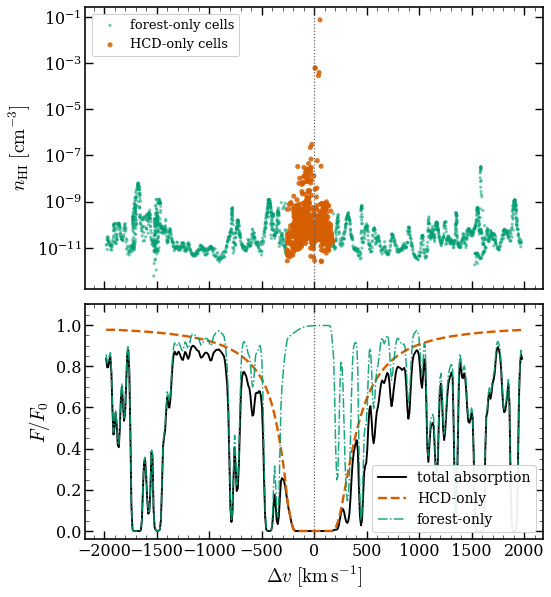


halo 25  log10 M200 = 12.21  R200 = 244.8 ckpc/h
sightline: axis 2, Left, b = 0.2530 R200
v_sys = 550.6 km/s, fine alignment = +160.5 km/s
  None         log10 N_HI = 19.54
  HCD_only     log10 N_HI = 19.54
  Forest_only  log10 N_HI = 15.64


In [18]:
# =============================================================================
# CELL 6 -- FIG 2  (plots/HCD_detection_altHalo.png)
#
# Identical to 01.5_TNG50_individual.ipynb's Cell 8. Re-run after CELL 4, or
# on its own for style-only changes (XLIM_FIG2, colours, etc.).
#
# Elements drawn, all of which the caption must name:
#   green points     cells returned to the forest channel
#   orange points    cells the filter assigned to the HCD channel
#   dotted vertical  the halo rest frame, after the alignment of Sec. 2.4
#   three curves     total, HCD-only and forest-only transmitted flux
# =============================================================================
plt.close('all')

LS = {"total": "-", "hcd": "--", "forest": "-."}

fig2, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(8.2, 9.6), sharex=True,
    gridspec_kw=dict(height_ratios=[1.2, 1.0], hspace=0.06))

ax0.scatter(x_for, n_for, s=10, color=OI["green"], alpha=0.55,
            edgecolor='none', rasterized=True, label='forest-only cells')
ax0.scatter(x_hcd, n_hcd, s=26, color=OI["vermillion"], alpha=0.85,
            edgecolor='none', rasterized=True, label='HCD-only cells')
ax0.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax0.set_yscale('log')
ax0.set_ylabel(r'$n_{\rm HI}\ [\mathrm{cm^{-3}}]$')
ax0.legend(loc='upper left', fontsize=13, handletextpad=0.5)

ax1.plot(v_grid, flux_c["None"], color=OI["black"], lw=1.9,
         ls=LS["total"], label='total absorption')
ax1.plot(v_grid, flux_c["HCD_only"], color=OI["vermillion"], lw=2.4,
         ls=LS["hcd"], label='HCD-only')
ax1.plot(v_grid, flux_c["Forest_only"], color=OI["green"], lw=1.5, alpha=0.9,
         ls=LS["forest"], label='forest-only')
ax1.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax1.set_ylim(-0.04, 1.10)
ax1.set_ylabel(r'$F/F_0$')
ax1.set_xlabel(r'$\Delta v\ [\mathrm{km\,s^{-1}}]$')
ax1.legend(loc='lower right', fontsize=14)

if XLIM_FIG2 is not None:
    ax0.set_xlim(*XLIM_FIG2)

for ax in (ax0, ax1):
    ax.grid(False)
    for s in ax.spines.values():
        s.set_linewidth(1.6)

out2 = os.path.join(PLOT_DIR, "HCD_detection_altHalo.png")
fig2.savefig(out2, dpi=300, bbox_inches='tight')
if hasattr(fig2.canvas, "header_visible"):
    fig2.canvas.header_visible = False
print(f"saved {out2}")
plt.show()

# Numbers for the captions
print(f"\nhalo {halo_info['id']}  log10 M200 = "
      f"{np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}  "
      f"R200 = {r200 * ctx.length_unit_kpc:.1f} ckpc/h")
print(f"sightline: axis {AXIS}, {position}, b = {B_USED:.4f} R200")
print(f"v_sys = {V_SYS:.1f} km/s, fine alignment = {dv_shift:+.1f} km/s")
for mode in MODES:
    tot = res[mode]["colden"].sum()
    print(f"  {mode:12s} log10 N_HI = "
          f"{np.log10(tot) if tot > 0 else -np.inf:.2f}")


In [19]:
# =============================================================================
# CELL 7 -- position-space prep (chi_hcd/chi_for/basins) for CELL 8
#
# Unchanged from 01.5_TNG50_individual.ipynb's Cell 9.
#
#   chi_coords      the same wrap(pos - cm, box) used inside CELL 5's
#                   cell_coords, but left as a POSITION (ckpc/h) instead of
#                   turned into a velocity -- the fine-alignment shift
#                   (dv_shift) is a redshift-space correction and has no
#                   real-space analogue, so it is not applied here.
#   basin_positions the fork records each basin's peak in box-frame redshift
#                   space (peak_kms = velfac*x + v_pec at the profile
#                   maximum), which has no unique inverse back to a position.
#                   Instead every captured cell is assigned to its nearest
#                   basin peak in wrapped u-space -- the same coordinate the
#                   watershed of CELL 4 itself works in -- and each basin's
#                   marker is placed at the N_HI-weighted mean chi of the
#                   cells assigned to it. This is a proxy for "where" the
#                   peak sits, not a re-run of the watershed.
# =============================================================================
def chi_coords(cells):
    """(chi [ckpc/h], n_HI [cm^-3]) for one captured cell set, halo rest frame."""
    if cells['pos'].shape[0] == 0:
        return np.empty(0), np.empty(0)
    chi = wrap(cells['pos'][:, k_los] - halo_info['cm'][k_los], box)
    return chi * ctx.length_unit_kpc, cells['nHI']


chi_hcd, _ = chi_coords(res["HCD_only"]["cells"])
chi_for, _ = chi_coords(res["Forest_only"]["cells"])

basins = list(meta.get('basin_info', {}).get(0, []))
n_accepted = sum(b['accepted'] for b in basins)
print(f"basins found for this sightline: {len(basins)}, "
      f"accepted into the HCD channel (entered the analysis): {n_accepted}")

basin_positions = []
if basins:
    pos_all = np.concatenate([res["HCD_only"]["cells"]["pos"],
                              res["Forest_only"]["cells"]["pos"]], axis=0)
    vel_all = np.concatenate([res["HCD_only"]["cells"]["vel"],
                              res["Forest_only"]["cells"]["vel"]], axis=0)
    nHI_all = np.concatenate([n_hcd, n_for])
    chi_all = np.concatenate([chi_hcd, chi_for])

    if pos_all.shape[0]:
        u_cell = np.mod(meta['velfac'] * pos_all[:, k_los] + vel_all[:, k_los],
                        meta['vmax'])
        peak_u = np.array([b['peak_kms'] for b in basins])
        du = np.abs(u_cell[:, None] - peak_u[None, :])
        du = np.minimum(du, meta['vmax'] - du)          # periodic in u
        nearest = np.argmin(du, axis=1)

        for bi, b in enumerate(basins):
            sel = nearest == bi
            if not sel.any():
                continue
            w = nHI_all[sel]
            chi_pk = float(np.sum(chi_all[sel] * w) / np.sum(w))
            basin_positions.append((b, chi_pk))
            print(f"  peak @ {b['peak_kms']:7.1f} km/s (box frame), "
                  f"log10 N_HI = {np.log10(max(b['N_HI'], 1e-300)):.2f}, "
                  f"chi ~ {chi_pk:+.1f} ckpc/h, "
                  f"{'ACCEPTED' if b['accepted'] else 'rejected'}"
                  f"{'' if b['in_window'] else ' (outside halo window)'}")


basins found for this sightline: 24, accepted into the HCD channel (entered the analysis): 1
  peak @  1740.7 km/s (box frame), log10 N_HI = 12.87, chi ~ +10708.3 ckpc/h, rejected (outside halo window)
  peak @  1880.7 km/s (box frame), log10 N_HI = 13.90, chi ~ +11420.3 ckpc/h, rejected (outside halo window)
  peak @  1950.8 km/s (box frame), log10 N_HI = 13.51, chi ~ +12198.7 ckpc/h, rejected (outside halo window)
  peak @  2060.8 km/s (box frame), log10 N_HI = 13.77, chi ~ +13202.0 ckpc/h, rejected (outside halo window)
  peak @  2290.9 km/s (box frame), log10 N_HI = 15.15, chi ~ +15356.9 ckpc/h, rejected (outside halo window)
  peak @  2611.0 km/s (box frame), log10 N_HI = 14.49, chi ~ -16037.0 ckpc/h, rejected (outside halo window)
  peak @  2811.1 km/s (box frame), log10 N_HI = 13.72, chi ~ -15657.8 ckpc/h, rejected (outside halo window)
  peak @  2861.1 km/s (box frame), log10 N_HI = 13.25, chi ~ -15094.7 ckpc/h, rejected (outside halo window)
  peak @  2991.2 km/s (box frame), 

peak-merging ratio used (R = hcd_peak_contrast): 0.5
reconstructed watershed: 29 system(s) over the full periodic profile, AFTER that merging (fork reported 24 basin(s) for the halo-window search)

system cross-reference (top 29 by contributed column; the numbers annotated on FIG below):
 sys   chi_sys [ckpc/h]  v_peak_sys [km/s]  log10 N_HI(sys)  own-cell residual [km/s] (median, max)
   0            -6624.2             -861.1            13.94  34.9, 99.2
   1            -6066.8             -791.1            13.69  19.9, 59.8
   2            -4977.3             -671.0            13.29  34.8, 59.2
   3            -4089.1             -551.0            14.64  35.4, 70.0
   4            -3461.2             -450.9            13.93  28.5, 78.8
   5             -299.5             -260.9            13.78  38.7, 109.9
   6              414.4             -180.8            19.54  25.8, 59.2
   7              331.9              -80.8            14.16  15.5, 39.9
   8              344.5           

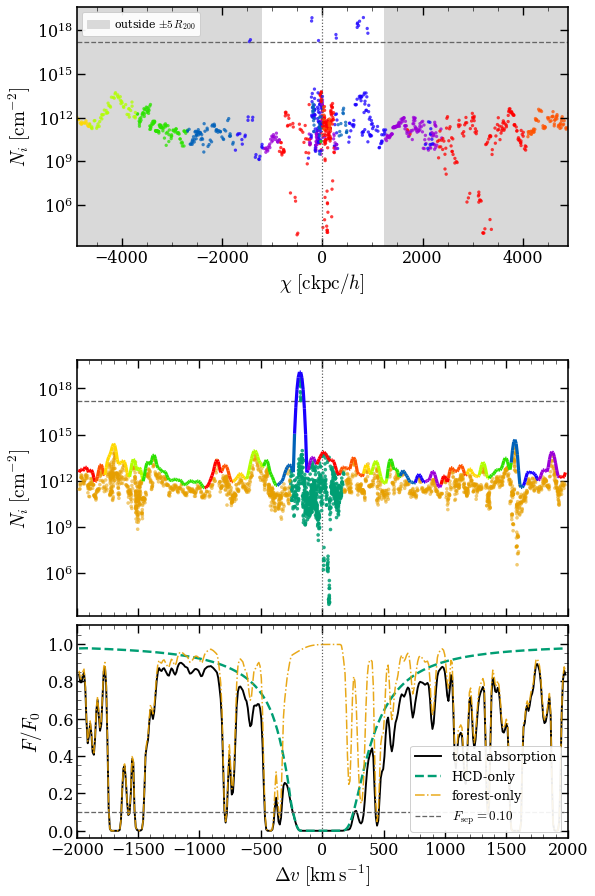

In [20]:
# =============================================================================
# CELL 8 -- FIG 2d (plots/HCD_detection_subDLA_3panel_systems.pdf)
#
# The sightline plotted here is whatever CELL 4's search landed on (a clean,
# single-region Sub-DLA), not CELL 3's default -- res/meta/halo_info/k_los/
# box/etc. were all overwritten there. Reproduced from 01.5_'s Cell 11
# (its own "CELL 11 -- FIG 2d"), unchanged except for cell numbers in the
# prose below and the output filename.
#
# Advisor's spec for this figure:
#   Panel 1 (top, real space)   N_i vs chi. Every point is coloured by the
#                                SYSTEM (watershed basin) it is assigned to --
#                                the colour comes from the segmentation, not
#                                from anything measured in real space. Plotted
#                                as N_i (the column each cell CONTRIBUTES, cm^-2,
#                                same quantity as panel 2 -- not the cell's own
#                                density n_HI, cm^-3): a cell can be dense but
#                                only graze the sightline through a thin chord,
#                                contributing little column, and n_HI alone would
#                                hide that. Shows
#                                where the gas actually is; the +/-5 R200
#                                window is shaded grey outside it. Zoomed to
#                                +/-20 R200 so the region around the halo is
#                                actually legible.
#   Panel 2 (middle, velocity)  2.1 the SAME cells, now plotting the
#                                contributed column N_i vs u = a H(z) chi +
#                                v_pec, points coloured by CHANNEL (HCD-only
#                                vs forest-only -- see NO BACKGROUND BANDS
#                                below for why this replaced a peculiar-
#                                velocity colour scale).
#                                2.2 the smoothed profile the watershed itself
#                                runs on, overplotted, coloured segment by
#                                segment to match the system it belongs to --
#                                this is the ONLY place system identity is
#                                conveyed in panels 2-3 (no background bands;
#                                see NO BACKGROUND BANDS below), so the line is
#                                drawn thick; a small black X marks every
#                                valley (region boundary) the watershed
#                                actually split on.
#   Panel 3 (bottom, flux)      Total / HCD-only / Forest-only, F_sep as a
#                                horizontal grey dashed line.
#
# NO BACKGROUND BANDS. Panels 2-3 used to also carry one shaded vertical band
# per system behind the curves, in the same palette as panel 1. Two colour
# cues (band + line/points) for the same information was doing the panel-1
# job twice and cluttering panels 2-3 without adding anything panel 1 does not
# already show; system identity in panels 2-3 now lives ONLY in the smoothed
# profile's segment colouring (panel 1 keeps its own per-point colouring,
# which is the one place it belongs). The profile line is drawn noticeably
# thicker than before (PROF_LW) to carry that job on its own.
#
# REPRODUCING THE WATERSHED WITHOUT TOUCHING THE FORK. _velocity_watershed
# (spectra.py:1032) is a @staticmethod: it can be called directly on our own
# profile, no fork edit needed. The merging ratio ("R") IS applied: it is
# meta['peak_contrast'], read straight off the Spectra instance that produced
# this sightline (ss.hcd_peak_contrast, spectra.py:159, carried in meta since
# CELL 3 and reused unchanged by CELL 4's search) -- never hardcoded here --
# so this reconstruction is already the after-merging segmentation, whatever
# R the run actually used. The number of elementary systems this returns can
# legitimately be large: every surviving local maximum of the FULL periodic
# column-density profile counts, and only the strongest (and halo-local) ones
# ever get accepted as an HCD -- printed below for a sanity check against
# meta['basin_info'].
#
# The profile _velocity_watershed needs is exactly what _hcd_peak_mask bins
# internally (spectra.py:1099-1103): a per-pixel column density, box frame,
# smoothed by hcd_peak_smooth_kms (meta['peak_smooth_kms']). We do not have
# the per-cell column _cell_column relies on (it needs the smoothing length
# and impact parameter; capture_cells, CELL 1, stores neither), but its own
# docstring says "sum(_cell_column) == sum(get_col_density) to machine
# precision for the tophat kernel" (spectra.py:1004-1006), and KERNEL =
# "tophat" here, so res["None"]["colden"] (CELL 3/CELL 4) IS that profile.
#
# FIX (systematic rightward offset of the smoothed curve): CELL 5 aligns
# array-valued quantities to the halo frame in TWO steps -- center_on_halo
# (aligns to V_SYS) and then, only if the fine-alignment trigger fired, an
# extra reshift by dv_shift (the trough-centring correction; see flux_c in
# CELL 5). The previous version of this cell only did the first step for
# the smoothed profile, while every scattered quantity (x_hcd/x_for, and
# therefore dv_cells below) already carries both -- an offset of exactly
# dv_shift between the curve and the points. Fixed by applying the same two
# steps here.
#
# PER-CELL CONTRIBUTED COLUMN. With no per-cell _cell_column available
# either, N_i below instead splits each pixel's REAL column (from the
# profile above) across the cells landing in it, weighted by their physical
# n_HI: exact in aggregate (sum(N_i) over a pixel reproduces that pixel's
# real column to the last decimal), approximate only in how that column is
# divided among cells sharing a pixel.
#
# F_sep is hcd_blend_flux_thresh (meta['blend_flux_thresh']): the flux level
# the _blend_test of CELL 3/CELL 4 requires the spectrum to recover to
# between two candidate components for them to count as separable
# (spectra.py:1164-1172).
#
# COLOUR CHOICE (per-SYSTEM: panel 1's points, panel 2's profile segments).
# Labels come out of _velocity_watershed in u-order (the merge loop only
# ever pops from a position-sorted peak list, so surviving label i and i+1
# are adjacent in velocity -- spectra.py:1070-1081). The previous hsv-sampled
# palette placed system i and i+1 at nearby hues whenever n_sys was large
# (small angular step), which is exactly backwards: adjacent systems are the
# pair the eye most needs to tell apart. 'prism' (matplotlib's own
# recommendation for labelled/segmented data) is the classic MATLAB-style
# repeating colormap: red -> orange -> yellow -> yellow-green -> green ->
# teal -> blue -> violet, then back to red, cycling roughly every 0.098 of
# [0, 1] (detected at runtime below, not hardcoded, in case matplotlib's LUT
# for it ever changes). Naively sampling it like hsv (cmap(i / n_colors) for
# i in range(n_colors)) very nearly ALIASES that short native period whenever
# n_colors is itself close to a multiple of ~10 -- exactly our case with
# ~20-30 systems -- so consecutive systems would land almost back on the SAME
# point of one cycle and look like a smooth gradient rather than jumping
# colours (this was tried first and looked wrong). Fixed by sampling
# N_HUES=8 anchors evenly spaced WITHIN one native period (giving the 8
# maximally-separated colours above) and cycling system i through those 8 by
# i % N_HUES, so system i and i+1 always land on two different anchors,
# never on two near-identical shades. The same palette drives panel 1's
# points and panel 2's curve segments, so a system keeps one colour
# everywhere it appears.
#
# CHANNEL/TOTAL COLOURS (panels 2-3 only) are separate from the per-system
# palette above and use the same N_HI-class hex values as 01.5_'s
# CLASS_COLORS (Forest #E69F00, LLS #56B4E9, Sub_DLA #009E73, Small_DLA
# #F0E442, Large_DLA #0072B2), via radii_skewers.categorize: forest-only is
# by construction below the HCD cut, so it is always "Forest"; HCD-only is
# whichever class CELL 4's search actually landed on (a Sub-DLA here, hence
# green) -- computed from res["HCD_only"]["colden"].sum(), never hardcoded,
# so it stays correct if CELL 4's target range ever changes. Total stays
# plain black.
#
# SHARED X-AXIS FIX. ax_flux already had sharex=ax_vel, but the colourbar
# attached only to ax_vel (fig.colorbar's `fraction` steals width from its
# parent axes) shrank ax_vel without touching ax_flux, so despite sharing
# the same x-DATA range the two panels visibly drifted apart on the page.
# Fixed by explicitly pinning ax_flux's x0/width to ax_vel's post-colourbar
# position once layout has settled.
# =============================================================================
from scipy.ndimage import gaussian_filter1d
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

plt.close('all')

# --- reproduce the watershed on the real column-density profile ------------
dv_bin = meta['vmax'] / meta['nbins']
prof_raw = np.asarray(res["None"]["colden"], dtype=float)      # box frame
sigma_pix = meta['peak_smooth_kms'] / dv_bin
prof_smooth = (gaussian_filter1d(prof_raw, sigma_pix, mode='wrap')
              if sigma_pix > 1e-3 else prof_raw.copy())

labels_box, peak_pix_box = spectra.Spectra._velocity_watershed(
    prof_smooth, meta['peak_contrast'])
n_sys = max(int(labels_box.max()) + 1, 0) if labels_box.size else 0
print(f"peak-merging ratio used (R = hcd_peak_contrast): {meta['peak_contrast']}")
print(f"reconstructed watershed: {n_sys} system(s) over the full periodic "
      f"profile, AFTER that merging (fork reported {len(basins)} basin(s) "
      f"for the halo-window search)")


def _prism_hue_anchors(n_hues=8):
    """N_HUES evenly-spaced, maximally-separated colours sampled from one
    native repeat of matplotlib's 'prism' cmap -- see COLOUR CHOICE above."""
    prism = mpl.colormaps['prism']
    c0 = np.array(prism(0.0))[:3]
    probe = np.linspace(0.02, 1.0, 2000)   # skip x~0, prism is flat there
    period = next((x for x in probe
                   if np.allclose(np.array(prism(x))[:3], c0, atol=0.03)), 1.0)
    return [prism(k * period / n_hues) for k in range(n_hues)]


N_HUES = 8
hue_anchors = _prism_hue_anchors(N_HUES)

n_colors = max(n_sys, 1)
palette = [hue_anchors[i % N_HUES] for i in range(n_colors)]
sys_cmap = ListedColormap(palette)
sys_norm = BoundaryNorm(np.arange(-0.5, len(palette) + 0.5, 1.0), sys_cmap.N)


def sys_color(i):
    return palette[int(i) % len(palette)]


# --- N_HI-class colours for the CHANNEL/TOTAL curves only (panels 2-3) --
# same pattern as 01.5_'s CLASS_COLORS, independent of the per-system prism
# palette above -- see CHANNEL/TOTAL COLOURS above.
CLASS_COLORS = {
    "Forest":    "#E69F00",
    "LLS":       "#56B4E9",
    "Sub_DLA":   "#009E73",
    "Small_DLA": "#F0E442",
    "Large_DLA": "#0072B2",
}


def logNHI_class_color(total_colden):
    """CLASS_COLORS entry for one absorber's total N_HI [cm^-2]."""
    lg = max(float(np.log10(total_colden)), 0.0) if total_colden > 0 else 0.0
    label = str(radii_skewers.categorize([lg])[0])
    return CLASS_COLORS[label]


hcd_color = logNHI_class_color(res["HCD_only"]["colden"].sum())
forest_color = CLASS_COLORS["Forest"]


# --- per-cell quantities: box-frame u, pixel index, system id --------------
pos_cells = np.concatenate([res["HCD_only"]["cells"]["pos"],
                            res["Forest_only"]["cells"]["pos"]], axis=0)
vel_cells = np.concatenate([res["HCD_only"]["cells"]["vel"],
                            res["Forest_only"]["cells"]["vel"]], axis=0)
nHI_cells = np.concatenate([n_hcd, n_for])
chi_cells = np.concatenate([chi_hcd, chi_for])        # ckpc/h, real space
dv_cells = np.concatenate([x_hcd, x_for])             # km/s, u = aH(z)chi + v_pec

u_box_cells = np.mod(meta['velfac'] * pos_cells[:, k_los] + vel_cells[:, k_los],
                     meta['vmax'])
kpix_cells = np.minimum((u_box_cells / dv_bin).astype(np.intp),
                        meta['nbins'] - 1)
sys_id_cells = labels_box[kpix_cells] if n_sys else np.zeros(len(kpix_cells), int)

pixel_nHI_sum = np.bincount(kpix_cells, weights=nHI_cells,
                            minlength=meta['nbins'])
safe_sum = np.where(pixel_nHI_sum > 0, pixel_nHI_sum, 1.0)
N_i_cells = nHI_cells * (prof_raw[kpix_cells] / safe_sum[kpix_cells])


# --- CROSS-REFERENCE + SELF-CONSISTENCY CHECK ------------------------------
# Panel 1's x-axis is chi (real-space position, uncorrected for dv_shift).
# Panels 2-3's x-axis is v_grid (fully aligned: V_SYS AND dv_shift already
# removed -- see box_u_of_grid below). The same system can sit at very
# different-looking x-positions in the two coordinate systems, so eyeballing
# "the peak near the middle" across panels is not a valid way to check that
# colours agree. This block computes, per system, WHERE it sits in each of
# the two coordinates (chi_sys, v_peak_sys) and prints a table + a numeric
# check that a system's own cells (dv_cells, the exact x used for panel 2's
# scattered points) actually land on its own v_peak_sys -- if that check
# fails by more than a pixel or two, that is a real bug, not a palette or
# axis-choice artefact.
sys_total_col = (np.bincount(sys_id_cells, weights=N_i_cells, minlength=n_sys)
                 if n_sys else np.zeros(0))
chi_sys = np.full(n_sys, np.nan)
for _i in range(n_sys):
    _sel = sys_id_cells == _i
    if _sel.any():
        chi_sys[_i] = (np.sum(chi_cells[_sel] * N_i_cells[_sel])
                       / np.sum(N_i_cells[_sel]))
v_peak_sys = (wrap(peak_pix_box * dv_bin - V_SYS - dv_shift, meta['vmax'])
             if n_sys else np.zeros(0))

N_LABEL = n_sys  # label every system -- see the CROSS-REFERENCE note above:
                # colour alone cannot disambiguate 26 systems with 8 hues,
                # but a unique integer id always can, however many there are.
label_ids = (np.argsort(sys_total_col)[::-1][:N_LABEL]
            if n_sys else np.array([], dtype=int))

print(f"\nsystem cross-reference (top {N_LABEL} by contributed column; the"
      " numbers annotated on FIG below):")
print(f"{'sys':>4} {'chi_sys [ckpc/h]':>18} {'v_peak_sys [km/s]':>18} "
      f"{'log10 N_HI(sys)':>16}  own-cell residual [km/s] (median, max)")
for _i in sorted(label_ids):
    _dv = dv_cells[sys_id_cells == _i]
    if _dv.size:
        _resid = np.abs(wrap(_dv - v_peak_sys[_i], meta['vmax']))
        _resid_str = f"{np.median(_resid):.1f}, {_resid.max():.1f}"
    else:
        _resid_str = "no cells"
    print(f"{_i:4d} {chi_sys[_i]:18.1f} {v_peak_sys[_i]:18.1f} "
          f"{np.log10(max(sys_total_col[_i], 1e-300)):16.2f}  {_resid_str}")
print("(residual should be <~ dv_bin =", f"{dv_bin:.1f} km/s; if it isn't, the"
      " box-frame<->halo-frame inversion below has a real bug, not just an"
      " axis/palette mismatch.)")

# --- halo-frame velocity grid: nearest-neighbour system id + smoothed curve
box_u_of_grid = np.mod(v_grid + dv_shift + V_SYS, meta['vmax'])
box_idx_of_grid = np.minimum((box_u_of_grid / dv_bin).astype(np.intp),
                             meta['nbins'] - 1)
labels_grid = (labels_box[box_idx_of_grid] if n_sys
              else np.zeros_like(box_idx_of_grid))


def to_halo_frame(y):
    """center_on_halo, THEN the same fine-alignment reshift CELL 5 applies
    to flux_c -- both steps, or the curve lands dv_shift away from the
    points (see the FIX note above)."""
    y_c = center_on_halo(y)
    gg = np.concatenate([v_grid - meta['vmax'], v_grid, v_grid + meta['vmax']])
    return np.interp(v_grid, gg - dv_shift, np.concatenate([y_c, y_c, y_c]))


profile_grid = to_halo_frame(prof_smooth)

F_SEP = meta['blend_flux_thresh']

# velocity panels get a local window (panel 1 stays full-range -- its whole
# point is to show where the gas actually sits, including far outside it).
vel_lo, vel_hi = XLIM_FIG2 if XLIM_FIG2 is not None else (-2000.0, 2000.0)

fig5 = plt.figure(figsize=(8.8, 15.0))
gs = fig5.add_gridspec(2, 1, height_ratios=[1.1, 2.2], hspace=0.32)
ax_pos = fig5.add_subplot(gs[0])
# panels 2-3 share their x-axis (velocity) -- a nested gridspec lets THEM sit
# almost flush (hspace=0.04) while panel 1 (a different, real-space x-axis)
# keeps the wider gap above.
gs_vf = gs[1].subgridspec(2, 1, height_ratios=[1.2, 1.0], hspace=0.04)
ax_vel = fig5.add_subplot(gs_vf[0])
ax_flux = fig5.add_subplot(gs_vf[1], sharex=ax_vel)

# --- panel 1: real space, coloured by system, +/-5R200 shaded outside,
# zoomed to +/-20 R200 -----------------------------------------------------
ax_pos.scatter(chi_cells, N_i_cells, s=11, c=sys_id_cells, cmap=sys_cmap,
              norm=sys_norm, alpha=0.75, edgecolor='none', rasterized=True)
ax_pos.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax_pos.set_yscale('log')
ax_pos.axhline(10 ** HCD_LOG_NHI, color='0.4', lw=1.3, ls='--', zorder=2)
ax_pos.set_xlabel(r'$\chi\ [\mathrm{ckpc}/h]$')
ax_pos.set_ylabel(r'$N_i\ [\mathrm{cm^{-2}}]$')

zoom_ckpc = 20.0 * r200 * ctx.length_unit_kpc
ax_pos.set_xlim(-zoom_ckpc, zoom_ckpc)
xlim_pos = ax_pos.get_xlim()
window_ckpc = MAP_SLAB_R200 * r200 * ctx.length_unit_kpc
ax_pos.axvspan(xlim_pos[0], -window_ckpc, color='0.85', zorder=0)
ax_pos.axvspan(window_ckpc, xlim_pos[1], color='0.85', zorder=0,
              label=fr'outside $\pm{MAP_SLAB_R200:.0f}\,R_{{200}}$')
ax_pos.set_xlim(xlim_pos)
ax_pos.legend(loc='upper left', fontsize=11, handletextpad=0.5)

# --- panel 2: velocity space -------------------------------------------------
# System identity in panels 2-3 lives ONLY in the smoothed profile's segment
# colouring below (see NO BACKGROUND BANDS above) -- no axvspan bands here, no
# per-system number, no valley markers: colour alone is the cue.

# 2.1 per-cell points, coloured by channel (HCD-only vs forest-only), each
# channel's colour taken from the N_HI class of its own total column (see
# CHANNEL/TOTAL COLOURS above). dv_cells/N_i_cells are [HCD_only cells,
# Forest_only cells] concatenated in that order (see "per-cell quantities"
# above), so n_hcd.size is exactly where the split falls.
n_hcd_ct = n_hcd.size
ax_vel.scatter(dv_cells[:n_hcd_ct], N_i_cells[:n_hcd_ct], s=13,
              color=hcd_color, alpha=0.85, edgecolor='none',
              rasterized=True, zorder=6)
ax_vel.scatter(dv_cells[n_hcd_ct:], N_i_cells[n_hcd_ct:], s=13,
              color=forest_color, alpha=0.55, edgecolor='none',
              rasterized=True, zorder=6)

# smoothed profile, coloured segment by segment to match its system, drawn
# thick since it is now the only carrier of system colour in this panel --
# added AFTER the scatter (and at a higher zorder) so it draws on top of the
# points rather than being buried under them
PROF_LW = 3.2
points_prof = np.column_stack([v_grid, profile_grid])
segments_prof = np.stack([points_prof[:-1], points_prof[1:]], axis=1)
seg_colors = [sys_color(l) for l in
             (labels_grid[:-1] if n_sys else np.zeros(len(v_grid) - 1, dtype=int))]
prof_lc = LineCollection(segments_prof, colors=seg_colors, linewidths=PROF_LW, zorder=7)
ax_vel.add_collection(prof_lc)

ax_vel.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax_vel.axhline(10 ** HCD_LOG_NHI, color='0.4', lw=1.3, ls='--', zorder=2)
ax_vel.set_yscale('log')
ax_vel.set_ylabel(r'$N_i\ [\mathrm{cm^{-2}}]$')
plt.setp(ax_vel.get_xticklabels(), visible=False)

# --- panel 3: flux -----------------------------------------------------------
ax_flux.plot(v_grid, flux_c["None"], color=OI["black"], lw=1.9,
            ls=LS["total"], label='total absorption')
ax_flux.plot(v_grid, flux_c["HCD_only"], color=hcd_color, lw=2.4,
            ls=LS["hcd"], label='HCD-only')
ax_flux.plot(v_grid, flux_c["Forest_only"], color=forest_color, lw=1.5,
            alpha=0.9, ls=LS["forest"], label='forest-only')
ax_flux.axhline(F_SEP, color='0.4', lw=1.3, ls='--',
               label=fr'$F_{{\rm sep}} = {F_SEP:.2f}$')
ax_flux.axvline(0.0, color='0.35', lw=1.2, ls=':')
ax_flux.set_ylim(-0.04, 1.10)
ax_flux.set_ylabel(r'$F/F_0$')
ax_flux.set_xlabel(r'$\Delta v\ [\mathrm{km\,s^{-1}}]$')
ax_flux.legend(loc='lower right', fontsize=13)

ax_vel.set_xlim(vel_lo, vel_hi)

for ax in (ax_pos, ax_vel, ax_flux):
    ax.grid(False)
    for s in ax.spines.values():
        s.set_linewidth(1.6)

# pin ax_flux to ax_vel's post-colourbar x0/width -- see SHARED X-AXIS FIX
# note above; sharex alone is not enough once a colourbar shrinks ax_vel.
fig5.canvas.draw()
pos_vel, pos_flux = ax_vel.get_position(), ax_flux.get_position()
ax_flux.set_position([pos_vel.x0, pos_flux.y0, pos_vel.width, pos_flux.height])

out5 = os.path.join(DEFINITIVES_DIR, "HCD_detection_subDLA_3panel_systems.pdf")
fig5.savefig(out5, bbox_inches='tight')
if hasattr(fig5.canvas, "header_visible"):
    fig5.canvas.header_visible = False
print(f"saved {out5}")
plt.show()
